# 05 - Camada de negócio: CLV, custo/benefício, threshold ótimo e segmentação

Aqui o modelo vira decisão de **onde gastar o orçamento de retenção**.

Premissas (configuráveis em `src/business.py`):
- Margem sobre transações: **4%** ao ano; juros sobre saldo rotativo: **12%** ao ano;
- Anuidade média: Blue $50, Silver $80, Gold $120, Platinum $250;
- CLV = lucro anual × fator de anuidade **5 anos a 10%** de desconto;
- Custo de campanha: **$80** (contato personalizado) ou **$5** (automação);
- Lift de retenção: **15%** (personalizado) ou **5%** (automatizado), premissas de literatura.


In [1]:
%matplotlib inline
import sys, pathlib, os
ROOT = pathlib.Path(os.getcwd())
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

import features as fe
import business as bz
import train as T

RAW = ROOT / "data" / "raw" / "BankChurners.csv"
ART = ROOT / "artifacts"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)


CLV médio: $1,397  |  mediana $1,334
Lucro anual médio: $369


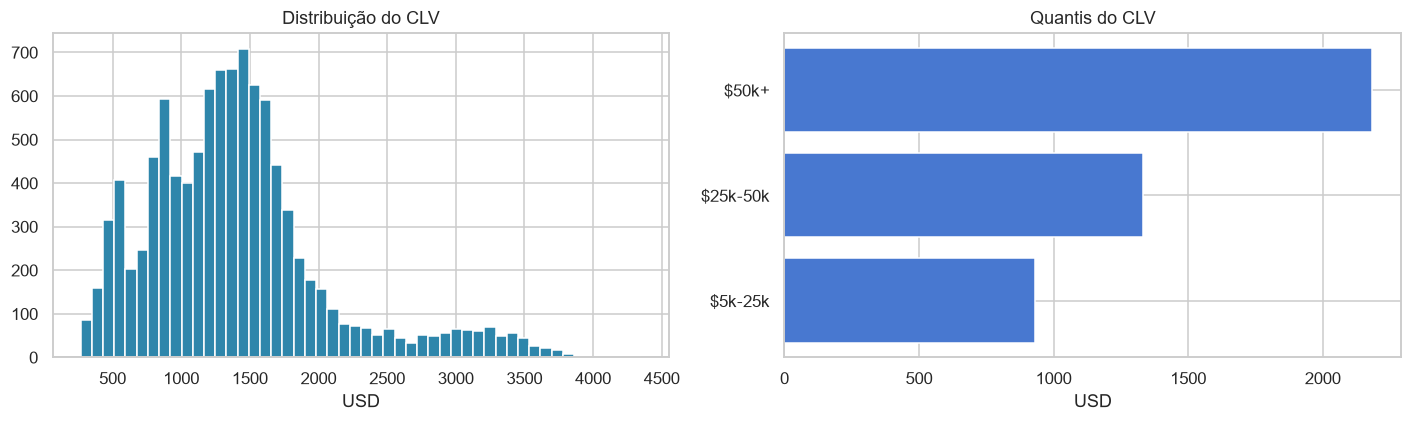

In [2]:
import json

raw = T.load_raw(RAW)
X, feature_columns = fe.build_features(raw)
X = X.reset_index(drop=True)

clv_all = T.compute_clv(raw)
print(f"CLV médio: ${clv_all.mean():,.0f}  |  mediana ${clv_all.median():,.0f}")
print(f"Lucro anual médio: ${bz.annual_profit(raw['Total_Trans_Amt'], raw['Total_Revolving_Bal'], raw['Card_Category'].str.strip()).mean():,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(clv_all, bins=50, color="#2e86ab")
axes[0].set_title("Distribuição do CLV")
axes[1].barh(["$5k-25k", "$25k-50k", "$50k+"], [clv_all.quantile(q) for q in [0.25, 0.5, 0.9]])
axes[1].set_title("Quantis do CLV")
for ax in axes:
    ax.set_xlabel("USD")
plt.tight_layout()
plt.savefig(FIG / "clv_dist.png", bbox_inches="tight")
plt.show()


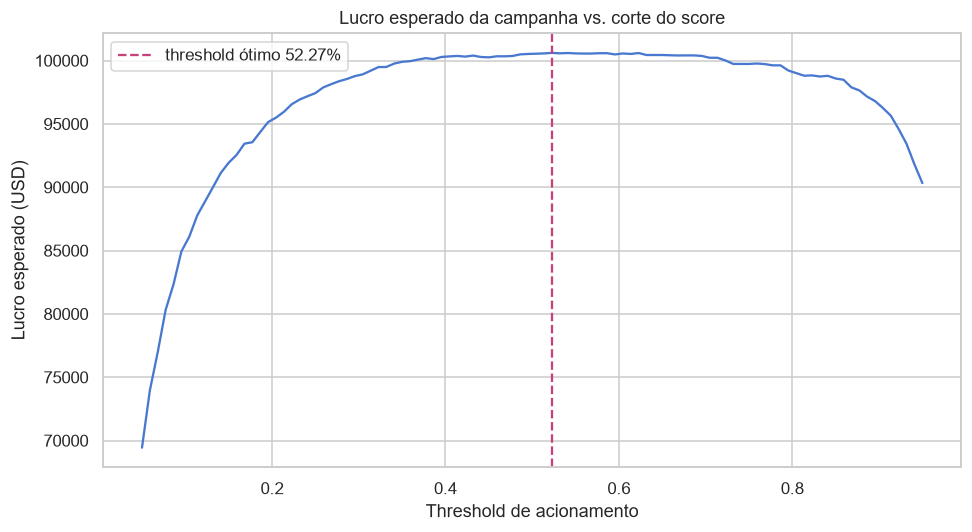

Threshold ótimo global: 52.27%  (EV máximo ~$100,608 na simulação)


In [3]:
# Curva de lucro esperado vs. threshold (população completa, acção "prioritária")
medians = json.loads((ART / "medians.json").read_text())
import joblib
model = joblib.load(ART / "churn_model.pkl")
score_all = T.churn_proba(model, fe.impute_medians(X, medians))
clv_np = clv_all.to_numpy()

ts = np.linspace(0.05, 0.95, 100)
evs = [bz.expected_value_on_threshold(score_all, clv_np, bz.RETENTION_COST_PRIORITARY, bz.LIFT_PRIORITARY, t) for t in ts]
t_opt = ts[int(np.argmax(evs))]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ts, evs)
ax.axvline(t_opt, color="#c7417b", ls="--", label=f"threshold ótimo {t_opt:.2%}")
ax.set_xlabel("Threshold de acionamento"); ax.set_ylabel("Lucro esperado (USD)")
ax.set_title("Lucro esperado da campanha vs. corte do score")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "ev_threshold.png", bbox_inches="tight")
plt.show()
print(f"Threshold ótimo global: {t_opt:.2%}  (EV máximo ~${max(evs):,.0f} na simulação)")


In [4]:
# Políticas comparadas na holdout (dados reais já persistidos)
bp = bz.load_business_params(ART / "business_params.json")
sc = bp["cenarios_holdout"]
pd.DataFrame({
    "Política": ["Não fazer nada", "Threshold global ótimo", "Regra por-cliente (lift·p·CLV > custo)"],
    "EV esperado (USD)": [sc["do_nothing_ev"], sc["ev_global_threshold_prioritary"], sc["ev_prioritary_per_client"]],
    "Clientes acionados": ["0", f"~{sc['n_prioritary_per_client']}", sc["n_prioritary_per_client"]],
})


,Política,EV esperado (USD),Clientes acionados
0,Não fazer nada,0.00,0
1,Threshold global ótimo,18985.16,~246
2,Regra por-cliente (lift·p·CLV > custo),20685.90,246


monitorar_upsell        4588
monitorar               3897
acao_automatizada       1166
retencao_prioritaria     476
Name: count, dtype: int64


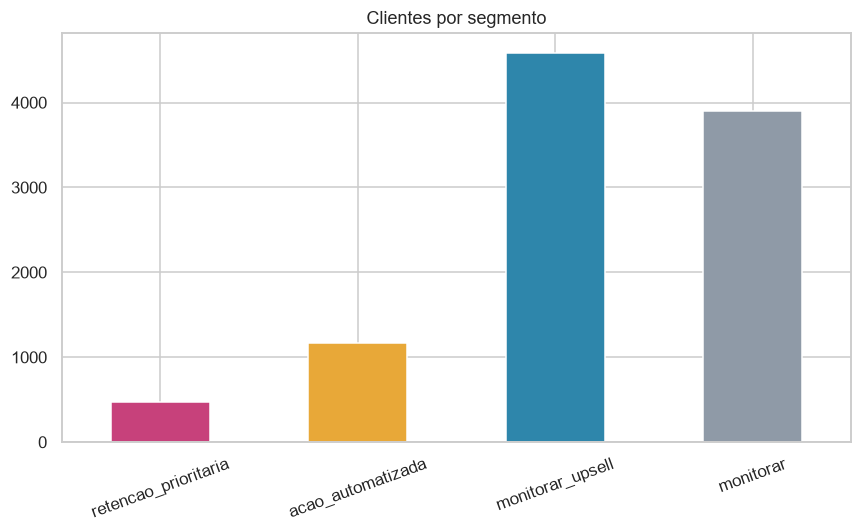

In [5]:
# Segmentação risco x valor (4 quadrantes) — população completa
final_score_all = score_all
seg_all = bz.segment_customers(final_score_all, clv_np, bp["risk_threshold"])
freq = seg_all.value_counts()
print(freq)

fig, ax = plt.subplots(figsize=(8, 5))
freq.reindex(bz.SEGMENTS).plot.bar(ax=ax, color=["#c7417b", "#e8a838", "#2e86ab", "#8f9aa7"])
ax.set_title("Clientes por segmento")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(FIG / "segmentos.png", bbox_inches="tight")
plt.show()


In [6]:
# ROI estimado da campanha por segmento (comparado a não agir)
roi = bz.campaign_roi(seg_all.to_numpy(), final_score_all, clv_np)
pd.DataFrame(roi).T.round(2)


,n_clientes,custo_total,retorno_esperado,roi
retencao_prioritaria,476.0,38080.0,119271.77,2.13
acao_automatizada,1166.0,5830.0,37558.96,5.44


In [7]:
# Contextualização Brasil (referência de moeda)
usd_brl = 5.2
ev = sc["ev_prioritary_per_client"]
print(f"EV da regra por-cliente na holdout: US${ev:,.0f} ≈ R${ev * usd_brl:,.0f}")
print(f"Custo por cliente (personalizado): US${bz.RETENTION_COST_PRIORITARY} ≈ R${bz.RETENTION_COST_PRIORITARY * usd_brl:.0f}")


EV da regra por-cliente na holdout: US$20,686 ≈ R$107,567
Custo por cliente (personalizado): US$80.0 ≈ R$416


### Regras operacionais recomendadas

1. **Acionar só quem compensa:** regra por-cliente `lift·p·CLV > custo` rende mais que qualquer
   corte fixo (EV $20,7k vs. $19,1k na holdout) — oposto de "reter todo mundo".
2. **Segmentos:**
   - `retencao_prioritaria` (alto risco × alto valor) → time humano, oferta personalizada;
   - `acao_automatizada` (alto risco × baixo valor) → oferta automática de baixo custo (email/app);
   - `monitorar_upsell` → não gastar agora, buscar expansão;
   - `monitorar` → sem ação.
3. **ROI:** com os lifts assumidos, o retorno esperado cobre folgadamente os custos nas duas
   campanhas (personalizada e automatizada).
4. **Corte operacional:** o alerta de retenção dispara com score `>= threshold` do modelo
   (persistido em `business_params.json`); a precisão nessa região (~0,90) limita o ruído
   para o time.
